# 01 · Datos y descriptivos

Arma la tabla de análisis del modelado: las 20 features acústicas CORE de cada tarea (`extraer_features.py`) unidas con las etiquetas clínicas de `baseDatos_tabular.xlsx`.

- **Prueba final sellada**: los 89 IDs de `prueba_final_ids.csv` se sacan **antes** de leer las etiquetas y no se vuelven a tocar hasta evaluar un único modelo ya fijado.
- **Targets**: depresión = PHQ-9 ≥ 10; ansiedad = GAD-7 ≥ 10. El sexo entra como variable de entrada.
- **Datos de menores**: este notebook se sube a GitHub con sus salidas, así que solo muestra conteos y estadísticos agregados (nunca filas con IDs ni puntajes).

Salida: `outputs/desarrollo.csv` (una fila por sujeto de desarrollo), que leen `02_explicativo` y `03_predictivo`.

## Housekeeping

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

import warnings
warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 160)

%matplotlib inline

In [2]:
# Rutas (relativas a esta carpeta)
FEATURES_CSV = Path("../feature-extraction-UA/outputs/features_core_completos.csv")
ETIQUETAS_XLSX = Path("../baseDatos_tabular.xlsx")
PRUEBA_FINAL = Path("prueba_final_ids.csv")
SALIDAS = Path("outputs")
SALIDAS.mkdir(exist_ok=True)

TAREAS = ["DESCRIPCION", "PREGUNTA1", "PREGUNTA2", "TEXTO_EL_ABUELO"]
FEATURES = [
    "F0semitoneFrom27.5Hz_sma3nz_amean", "F0semitoneFrom27.5Hz_sma3nz_stddevNorm",
    "F0semitoneFrom27.5Hz_sma3nz_pctlrange0-2", "jitterLocal_sma3nz_amean", "shimmerLocaldB_sma3nz_amean",
    "HNRdBACF_sma3nz_amean", "vw_a_f1_hz_mean", "vw_a_f2_hz_mean", "loudness_sma3_stddevNorm",
    "alphaRatioV_sma3nz_amean", "hammarbergIndexV_sma3nz_amean", "slopeV0-500_sma3nz_amean",
    "mfcc1V_sma3nz_amean", "mfcc2V_sma3nz_amean", "mfcc3V_sma3nz_amean", "mfcc4V_sma3nz_amean",
    "MeanVoicedSegmentLengthSec", "pause_time_ratio", "pause_mean_s", "articulation_rate_vps",
]
# Nombres cortos para tablas y gráficos
CORTO = {
    "F0semitoneFrom27.5Hz_sma3nz_amean": "F0_media", "F0semitoneFrom27.5Hz_sma3nz_stddevNorm": "F0_var",
    "F0semitoneFrom27.5Hz_sma3nz_pctlrange0-2": "F0_rango", "jitterLocal_sma3nz_amean": "jitter",
    "shimmerLocaldB_sma3nz_amean": "shimmer", "HNRdBACF_sma3nz_amean": "HNR", "vw_a_f1_hz_mean": "F1_a",
    "vw_a_f2_hz_mean": "F2_a", "loudness_sma3_stddevNorm": "loudness_var", "alphaRatioV_sma3nz_amean": "alpha_ratio",
    "hammarbergIndexV_sma3nz_amean": "hammarberg", "slopeV0-500_sma3nz_amean": "slope_0_500",
    "mfcc1V_sma3nz_amean": "mfcc1", "mfcc2V_sma3nz_amean": "mfcc2", "mfcc3V_sma3nz_amean": "mfcc3",
    "mfcc4V_sma3nz_amean": "mfcc4", "MeanVoicedSegmentLengthSec": "seg_sonoro", "pause_time_ratio": "pausa_ratio",
    "pause_mean_s": "pausa_media", "articulation_rate_vps": "vel_articulacion",
}

## 1. Features acústicas

Una fila por sujeto y tarea. `features_core_completos.csv` ya trae solo sujetos con las 4 tareas extraídas sin error.

In [3]:
feat = pd.read_csv(FEATURES_CSV, dtype={"participant_id": str})
print(f"Filas: {feat.shape[0]} | columnas: {feat.shape[1]} | sujetos: {feat['participant_id'].nunique()}")
print("Filas por tarea:", feat["task"].value_counts().to_dict())
print("Estados:", feat["estado"].value_counts().to_dict())
print("TextGrid:", feat["textgrid_estado"].str.split(" ").str[0].value_counts().to_dict())

# Prueba final sellada: fuera antes de mirar etiquetas
prueba = pd.read_csv(PRUEBA_FINAL, dtype={"participant_id": str})["participant_id"]
en_prueba = feat["participant_id"].isin(prueba)
print(f"\nPrueba final: {prueba.nunique()} IDs, {feat.loc[en_prueba, 'participant_id'].nunique()} con features completas")
feat = feat[~en_prueba].copy()
print(f"Desarrollo: {feat['participant_id'].nunique()} sujetos")

Filas: 1780 | columnas: 28 | sujetos: 445
Filas por tarea: {'DESCRIPCION': 445, 'PREGUNTA1': 445, 'PREGUNTA2': 445, 'TEXTO_EL_ABUELO': 445}
Estados: {'ok': 1780}
TextGrid: {'ok': 1771, 'textgrid_vacio': 7, 'tier_no_estandar': 2}

Prueba final: 89 IDs, 89 con features completas
Desarrollo: 356 sujetos


Valores faltantes por feature y tarea (los formantes de /a/ faltan si el audio no tiene /a/ anotadas; las pausas, si no hay silencios internos):

In [4]:
faltantes = feat.groupby("task")[FEATURES].apply(lambda g: g.isna().sum()).T.rename(index=CORTO)
display(faltantes[faltantes.sum(axis=1) > 0])
print("Features sin faltantes:", int((faltantes.sum(axis=1) == 0).sum()), "de", len(FEATURES))

task,DESCRIPCION,PREGUNTA1,PREGUNTA2,TEXTO_EL_ABUELO
F1_a,2,2,2,0
F2_a,2,2,2,0
pausa_media,1,0,0,0
vel_articulacion,2,1,2,0


Features sin faltantes: 16 de 20


Tasa de muestreo de los audios (la base mezcla equipos o configuraciones):

In [5]:
display(pd.crosstab(feat["tasa_muestreo_hz"], feat["task"], margins=True))
print("Duración (s) por tarea:")
display(feat.groupby("task")["duracion_s"].describe().round(1))

task,DESCRIPCION,PREGUNTA1,PREGUNTA2,TEXTO_EL_ABUELO,All
tasa_muestreo_hz,,,,,
22050.0,42,41,41,42,166
24000.0,1,0,0,1,2
44100.0,255,255,255,255,1020
48000.0,54,55,55,54,218
64000.0,4,5,5,4,18
All,356,356,356,356,1424


Duración (s) por tarea:


,count,mean,std,min,25%,50%,75%,max
task,,,,,,,,
DESCRIPCION,356.0,43.9,21.4,4.8,24.1,43.2,64.1,96.6
PREGUNTA1,356.0,94.2,48.4,9.3,55.5,101.3,125.3,438.6
PREGUNTA2,356.0,98.4,50.1,12.1,59.4,108.9,125.9,508.3
TEXTO_EL_ABUELO,356.0,53.3,17.9,29.4,43.4,49.5,59.9,268.6


## 2. Etiquetas clínicas

`cualestucodigo` del Excel se enlaza con `participant_id` (3 dígitos con ceros a la izquierda). La codificación de `SEXO` no está documentada: `sexo` = 1 si `SEXO` = 2, y 0 en otro caso (hay un caso con `SEXO` = 3, que queda en 0).

In [6]:
etq = pd.read_excel(ETIQUETAS_XLSX)
etq["participant_id"] = etq["cualestucodigo"].astype(int).astype(str).str.zfill(3)
etq = etq[["participant_id", "SEXO", "EDAD", "TOTALPHQ9", "TOTALGAD7"]]

ids = pd.Series(feat["participant_id"].unique(), name="participant_id")
sin_etiqueta = (~ids.isin(etq["participant_id"])).sum()
print(f"Sujetos de desarrollo sin fila en el Excel: {sin_etiqueta}")

etq = etq[etq["participant_id"].isin(ids)].copy()
etq["dep"] = (etq["TOTALPHQ9"] >= 10).astype(int)
etq["ans"] = (etq["TOTALGAD7"] >= 10).astype(int)
etq["sexo"] = (etq["SEXO"] == 2).astype(int)
print("SEXO en el Excel:", etq["SEXO"].value_counts().sort_index().to_dict())
print(f"EDAD faltante: {etq['EDAD'].isna().sum()} de {len(etq)}")

Sujetos de desarrollo sin fila en el Excel: 0
SEXO en el Excel: {1: 197, 2: 158, 3: 1}
EDAD faltante: 73 de 356


## 3. Tabla ancha (una fila por sujeto)

Cada feature se repite por tarea: `<feature>__<TAREA>` (20 × 4 = 80 columnas). La tasa de muestreo se guarda por tarea como referencia.

In [7]:
ancha = feat.pivot(index="participant_id", columns="task", values=FEATURES)
ancha.columns = [f"{f}__{t}" for f, t in ancha.columns]
tasa = feat.pivot(index="participant_id", columns="task", values="tasa_muestreo_hz")
tasa.columns = [f"tasa__{t}" for t in tasa.columns]
dur = feat.pivot(index="participant_id", columns="task", values="duracion_s")
dur.columns = [f"duracion__{t}" for t in dur.columns]

datos = (etq.set_index("participant_id")
         .join(ancha, how="inner").join(tasa).join(dur)
         .reset_index())
print(f"Tabla de análisis: {datos.shape[0]} sujetos × {datos.shape[1]} columnas")

Tabla de análisis: 356 sujetos × 96 columnas


## 4. Prevalencias

In [8]:
prev = pd.DataFrame({
    "n": [len(datos)] * 3,
    "casos": [datos["dep"].sum(), datos["ans"].sum(), (datos["dep"] & datos["ans"]).sum()],
}, index=["depresión (PHQ-9 ≥ 10)", "ansiedad (GAD-7 ≥ 10)", "ambas"])
prev["prevalencia"] = (prev["casos"] / prev["n"]).round(3)
display(prev)

print("Depresión × ansiedad:")
display(pd.crosstab(datos["dep"], datos["ans"], margins=True))
print("Prevalencia por sexo (indicador SEXO = 2):")
display(datos.groupby("sexo")[["dep", "ans"]].agg(["sum", "mean", "count"]).round(3))
print(f"Correlación de Spearman PHQ-9 – GAD-7: {datos['TOTALPHQ9'].corr(datos['TOTALGAD7'], method='spearman'):.3f}")

,n,casos,prevalencia
depresión (PHQ-9 ≥ 10),356,140,0.393
ansiedad (GAD-7 ≥ 10),356,106,0.298
ambas,356,94,0.264


Depresión × ansiedad:


ans,0,1,All
dep,,,
0,204,12,216
1,46,94,140
All,250,106,356


Prevalencia por sexo (indicador SEXO = 2):


dep              ans             
     sum   mean count sum   mean count
sexo                                  
0     98  0.495   198  71  0.359   198
1     42  0.266   158  35  0.222   158

Correlación de Spearman PHQ-9 – GAD-7: 0.858


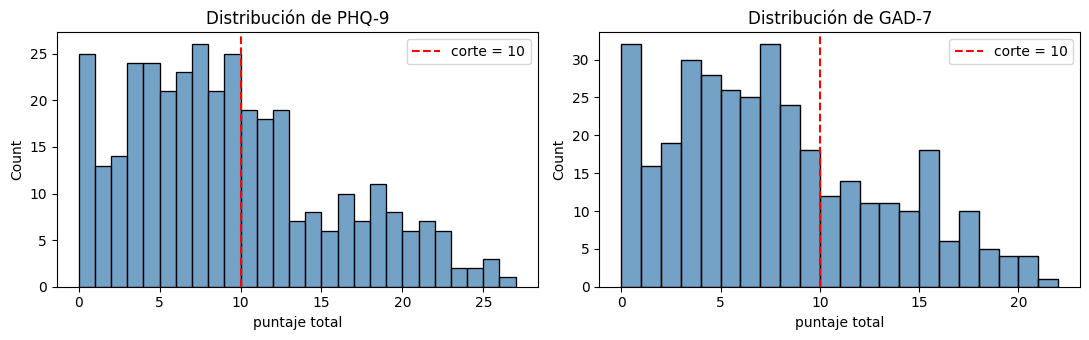

In [9]:
fig, ax = plt.subplots(1, 2, figsize=(11, 3.5))
for a, col, nombre in zip(ax, ["TOTALPHQ9", "TOTALGAD7"], ["PHQ-9", "GAD-7"]):
    sns.histplot(datos[col], bins=range(0, int(datos[col].max()) + 2), ax=a, color="steelblue")
    a.axvline(10, color="red", ls="--", label="corte = 10")
    a.set_title(f"Distribución de {nombre}"); a.set_xlabel("puntaje total"); a.legend()
plt.tight_layout(); plt.show()

## 5. Descriptivos de las features

Media, desviación estándar y rango de cada feature, juntando las 4 tareas:

In [10]:
desc = feat[FEATURES].describe().T[["mean", "std", "min", "50%", "max"]].rename(index=CORTO)
display(desc.round(3))

,mean,std,min,50%,max
F0_media,30.748,5.607,18.279,32.951,40.211
F0_var,0.123,0.037,0.035,0.118,0.316
F0_rango,3.493,1.778,1.163,3.135,19.796
jitter,0.034,0.011,0.013,0.032,0.099
shimmer,1.171,0.247,0.629,1.119,2.840
HNR,6.713,3.122,-3.521,7.360,13.234
F1_a,639.242,96.047,374.343,629.485,921.751
F2_a,1586.318,140.503,1231.815,1590.656,1967.637
loudness_var,0.819,0.171,0.328,0.799,1.657
alpha_ratio,-18.658,2.907,-28.940,-18.705,-11.174


### Diferencias entre grupos (d de Cohen)

d = (media en casos − media en no casos) / DE combinada, por feature y tarea. Es solo descriptivo: los contrastes ajustados por sexo y con corrección por comparaciones múltiples están en `02_explicativo`.

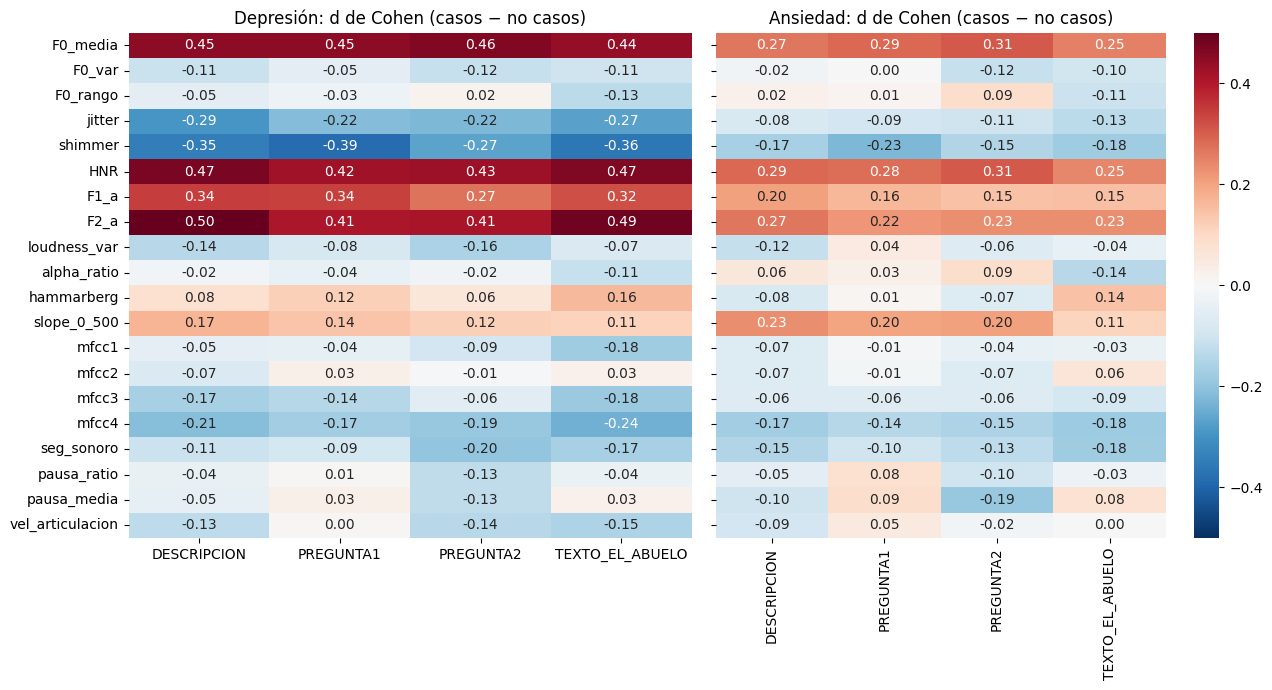

In [11]:
def cohen_d(x, g):
    a, b = x[g == 1].dropna(), x[g == 0].dropna()
    sp = np.sqrt(((len(a) - 1) * a.var() + (len(b) - 1) * b.var()) / (len(a) + len(b) - 2))
    return (a.mean() - b.mean()) / sp

fig, ax = plt.subplots(1, 2, figsize=(13, 7), sharey=True)
for a, obj, nombre in zip(ax, ["dep", "ans"], ["Depresión", "Ansiedad"]):
    d = pd.DataFrame({t: [cohen_d(datos[f"{f}__{t}"], datos[obj]) for f in FEATURES] for t in TAREAS},
                     index=[CORTO[f] for f in FEATURES])
    sns.heatmap(d, annot=True, fmt=".2f", cmap="RdBu_r", center=0, vmin=-0.5, vmax=0.5, ax=a, cbar=a is ax[-1])
    a.set_title(f"{nombre}: d de Cohen (casos − no casos)")
plt.tight_layout(); plt.show()

### Correlación entre features

Spearman con las 4 tareas juntas (una fila por sujeto y tarea):

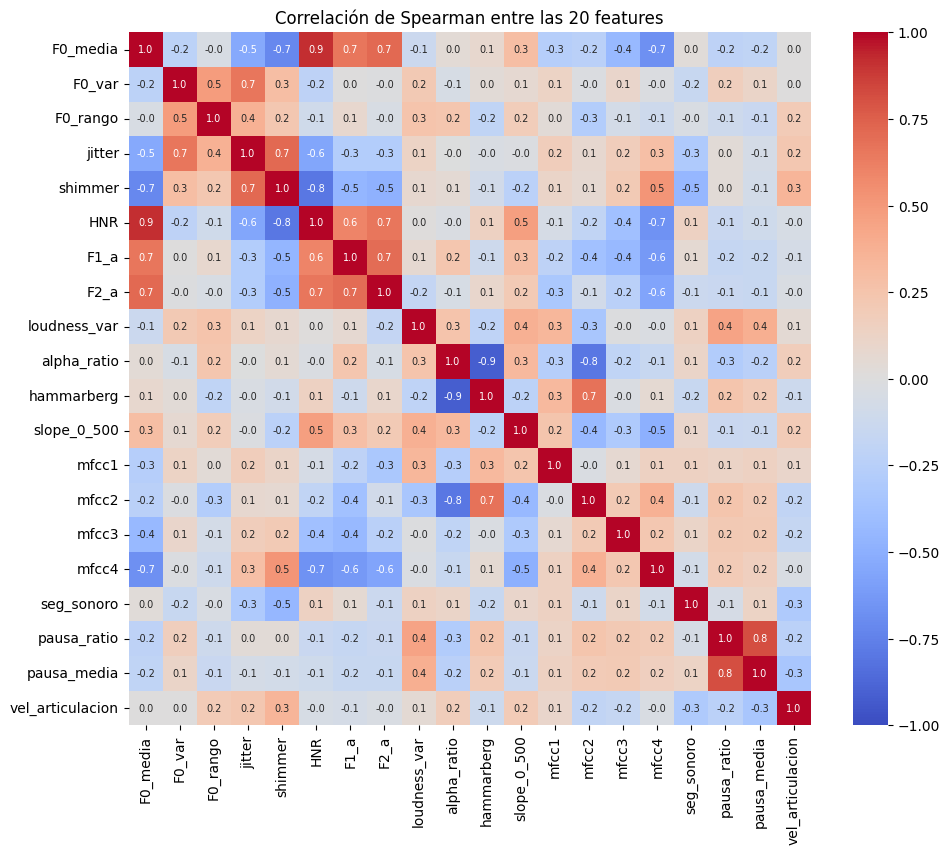

Pares con |rho| ≥ 0,7:


rho
alpha_ratio hammarberg  -0.919
F0_media    HNR          0.915
pausa_ratio pausa_media  0.820
shimmer     HNR         -0.804
alpha_ratio mfcc2       -0.798
F0_media    shimmer     -0.717
            F2_a         0.714
jitter      shimmer      0.713

In [12]:
corr = feat[FEATURES].rename(columns=CORTO).corr(method="spearman")
plt.figure(figsize=(11, 9))
sns.heatmap(corr, cmap="coolwarm", center=0, vmin=-1, vmax=1, annot=True, fmt=".1f", annot_kws={"size": 7})
plt.title("Correlación de Spearman entre las 20 features")
plt.show()

pares = corr.where(np.triu(np.ones(corr.shape, dtype=bool), 1)).stack()
print("Pares con |rho| ≥ 0,7:")
display(pares[pares.abs() >= 0.7].sort_values(key=abs, ascending=False).round(3).to_frame("rho"))

### Features según la tasa de muestreo

Media estandarizada (z) de cada feature por tasa de muestreo, con las 4 tareas juntas. Valores lejos de 0 indican que la feature cambia con el equipo o su configuración:

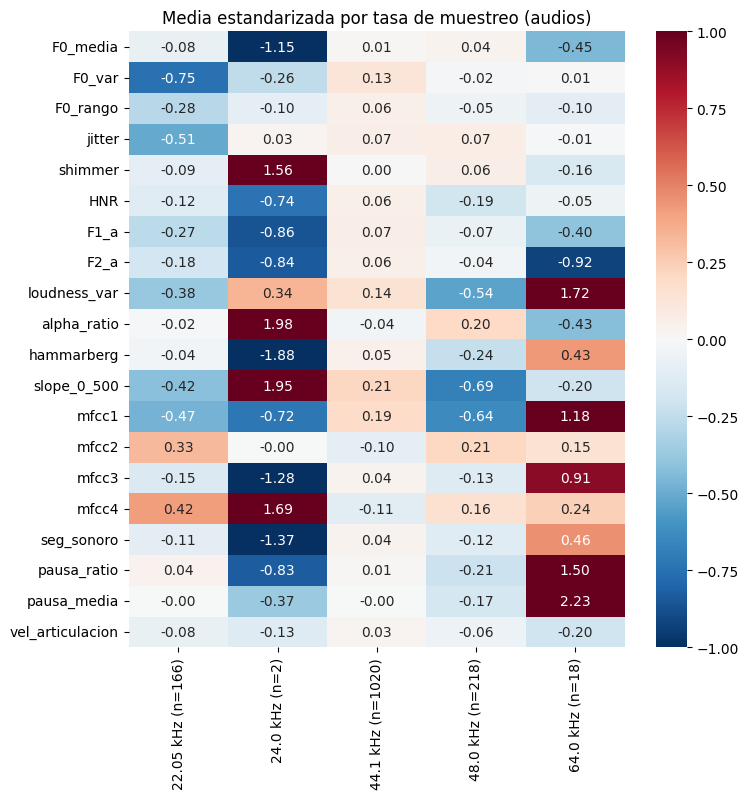

Prevalencia según la tasa de muestreo de PREGUNTA1 (solo grupos con 10 sujetos o más):


dep          ans      
                  mean count   mean count
tasa__PREGUNTA1                          
22050.0          0.268    41  0.244    41
44100.0          0.404   255  0.310   255
48000.0          0.455    55  0.309    55

Sujetos en grupos con menos de 10 (no se muestran): 5


In [13]:
z = feat[FEATURES].apply(lambda s: (s - s.mean()) / s.std())
z["tasa"] = (feat["tasa_muestreo_hz"] / 1000).round(2).astype(str) + " kHz"
tabla_tasa = z.groupby("tasa")[FEATURES].mean().rename(columns=CORTO).T
tabla_tasa.columns = [f"{c} (n={(z['tasa'] == c).sum()})" for c in tabla_tasa.columns]
plt.figure(figsize=(8, 8))
sns.heatmap(tabla_tasa, annot=True, fmt=".2f", cmap="RdBu_r", center=0, vmin=-1, vmax=1)
plt.title("Media estandarizada por tasa de muestreo (audios)")
plt.show()

print("Prevalencia según la tasa de muestreo de PREGUNTA1 (solo grupos con 10 sujetos o más):")
grupos = datos.groupby("tasa__PREGUNTA1")[["dep", "ans"]].agg(["mean", "count"])
display(grupos[grupos[("dep", "count")] >= 10].round(3))
print(f"Sujetos en grupos con menos de 10 (no se muestran): {int(grupos.loc[grupos[('dep', 'count')] < 10, ('dep', 'count')].sum())}")

## 6. Guardar la tabla de desarrollo

In [14]:
datos.to_csv(SALIDAS / "desarrollo.csv", index=False)
print(f"Guardado: {SALIDAS / 'desarrollo.csv'} | {datos.shape[0]} sujetos × {datos.shape[1]} columnas")

Guardado: outputs\desarrollo.csv | 356 sujetos × 96 columnas


## Lectura de resultados

**Muestra**
- 445 sujetos tienen las 4 tareas extraídas. Los 89 de la prueba final tienen features completas y se sacaron antes de leer etiquetas. Quedan **356 en desarrollo**, todos con fila en el Excel.
- Faltantes: F1/F2 de /a/ en 2 audios de DESCRIPCION, PREGUNTA1 y PREGUNTA2; `pausa_media` en 1; `vel_articulacion` en 5. Los otros 16 features están completos.
- Tasa de muestreo de los 1424 audios: 44,1 kHz 1020 (72 %), 48 kHz 218, 22,05 kHz 166, 64 kHz 18 y 24 kHz 2.

**Desenlaces**
- Depresión: 140 de 356 (0,393). Ansiedad: 106 (0,298). Ambas: 94.
- 94 de los 106 casos de ansiedad (89 %) también son casos de depresión. La correlación de Spearman PHQ-9 – GAD-7 es 0,858. Los dos targets se solapan mucho.
- `sexo` = 1 (SEXO = 2, codificación no documentada) tiene menor prevalencia: depresión 0,266 frente a 0,495 y ansiedad 0,222 frente a 0,359. Un caso con SEXO = 3 quedó como 0.

**Features**
- d de Cohen sin ajustar: el máximo |d| es 0,50 en depresión (F2 de /a/, DESCRIPCION) y 0,31 en ansiedad (F0 media, PREGUNTA2). Tienen |d| ≥ 0,2 26 de 80 combinaciones en depresión y 17 de 80 en ansiedad.
  - Ojo: F0 y formantes dependen del sexo, y el sexo se asocia con ambos desenlaces, así que estas d mezclan el efecto del sexo. El contraste ajustado está en `02_explicativo`.
- Hay redundancia fuerte: alpha ratio – Hammarberg ρ = −0,92, F0 media – HNR 0,92, pausa_ratio – pausa_media 0,82 y shimmer – HNR −0,80.
- Valores extremos:
  - `vel_articulacion` supera 12 vocales/s en 11 audios (p99 = 10,1; máximo 216,1), algo no plausible en habla real: probablemente la anotación o la detección de silencios fallan en esos audios.
  - `pausa_media` supera 3 s en 21 audios (máximo 10,8 s).
  - Están sin tratar: **queda por decidir** si se excluyen, se recortan (winsorizar) o se transforman.
- La prevalencia de depresión cambia con la tasa de muestreo de PREGUNTA1: 0,268 a 22,05 kHz (n = 41), 0,404 a 44,1 kHz (n = 255) y 0,455 a 48 kHz (n = 55). Como las features también cambian con la tasa, el equipo es un posible confusor (ver robustez en `02`).